# LevelLens: driver notebook

LevelLens estimates the target level of an exam question from its text: the exam stage, the school grade or the competition level. The levels are ordered, so a miss by one level is a smaller error than a miss by three.

This notebook has two parts.

1. **One small run from start to finish.** A made-up dataset, three models, the metrics, the table, a saved model and the explanation of one prediction. It needs no download and no GPU.
2. **The results of the project, rebuilt from the results store.** Every table, and every figure that needs no trained model. It reads `results/runs.jsonl` and the saved predictions in `results/preds/`. It needs no dataset and no model.

**How to run it.** Install the package as the [README](../README.md) says. Then run all cells, or type this in the repository root:

    jupyter nbconvert --to notebook --execute --inplace notebooks/main.ipynb

The whole notebook takes about one minute on a laptop CPU.

**What it writes.** Part 1 writes to `results/scratch/` and `cache/`, which git ignores. Part 2 rewrites `results/tables/` and `results/figures/` from the results store, so those files change only when the store has changed.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from levellens.config import compose
from levellens.data import info, load_split
from levellens.evaluate import evaluate, paired_bootstrap
from levellens.explain.local import explain
from levellens.figures import build_figures
from levellens.paths import results_dir, scratch_dir, shown
from levellens.predictor import Predictor
from levellens.results import build_tables, leaderboard, load_predictions, load_runs, predictions_file
from levellens.run import run

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 90)

## Part 1. One small run from start to finish

### 1.1 The data

Every dataset is read through `load_split` and gives items with the same fields. The toy dataset is generated in memory by `levellens/data/toy.py`. It has three levels, and its harder questions are longer and use rarer words. The real datasets (RACE++, ARC, MATH, ScienceQA) are downloaded once by `python -m levellens.data.prepare` and are then read in the same way.

In [2]:
DATASET = "toy"
levels = info(DATASET).level_names
train = load_split(DATASET, "train")
print(f"{len(train)} training items; levels, lowest first: {levels}")
pd.Series(train[0], name="the first training item")

240 training items; levels, lowest first: ('easy', 'medium', 'hard')


id                                                                      toy-train-000
dataset                                                                           toy
split                                                                           train
question                                  Which answer fits: eat measure big run red?
options                                                          [big, hat, cup, hat]
passage                                                                          None
text          Which answer fits: eat measure big run red? A. big B. hat C. cup D. hat
level                                                                               0
level_name                                                                       easy
meta                                                                    {'answer': 0}
Name: the first training item, dtype: object

In [3]:
per_level = {
    split: pd.Series([item["level_name"] for item in load_split(DATASET, split)]).value_counts()
    for split in ("train", "dev", "test")
}
pd.DataFrame(per_level).reindex(levels)

,train,dev,test
easy,80,20,30
medium,80,20,30
hard,80,20,30


- `text` is the model input: the question, then every option with its letter.
- `level` is the label: an integer from 0 to K − 1, from the lowest level to the highest.
- The splits are fixed. Settings are chosen on `dev`. `test` is for final numbers only.

### 1.2 A floor: always the most common level

One run is one call of `run` with a config. `compose` builds the config from the files in `configs/` and from `key=value` overrides. The command line does exactly the same:

    python -m levellens.run data=toy model=majority

A run trains the model, scores it on `dev`, `test` and `test_1k`, and appends one row to the results store. `test_1k` is a fixed subset of 1,000 test questions (the whole test split when it is smaller) on which every system is scored, the open LLM too. Runs on the toy dataset go to a store of their own, `results/scratch/`, so they never mix with the real results.

In [4]:
floor = run(compose(["data=toy", "model=majority"]))

toy-majority-none-s0: 240 training items, 3 levels, device cpu
toy-majority-none-s0: test accuracy 0.333, qwk 0.000, rmse 1.291, balanced_drps 1.000; trained in 0.0 s
toy-majority-none-s0: row written to results/scratch/runs.jsonl


In [5]:
print("fields of a result row:", ", ".join(floor))
pd.DataFrame({
    split: {name: value for name, value in metrics.items() if name != "per_level"}
    for split, metrics in floor["metrics"].items()
})

fields of a result row: run_id, started, owner, tier, dataset, model, head, variant, seed, config, metrics, train_seconds, predict_seconds, device, n_params, git_commit


,dev,test,test_1k
n,60.000000,90.000000,90.000000
accuracy,0.333333,0.333333,0.333333
macro_f1,0.166667,0.166667,0.166667
adjacent_accuracy,0.666667,0.666667,0.666667
qwk,0.000000,0.000000,0.000000
mae,1.000000,1.000000,1.000000
rmse,1.290994,1.290994,1.290994
spearman,NaN,NaN,NaN
spearman_score,NaN,NaN,NaN
drps,1.000000,1.000000,1.000000


The floor is right for one question in three, and its QWK is 0: it never tells two levels apart. Its Spearman correlation is undefined, because the prediction is constant. Every real model must beat this row.

### 1.3 A classical model: TF-IDF and logistic regression

The model is picked by its name. `configs/model/tfidf_logreg.yaml` names the class and its settings: word 1–2-grams and character 3–5-grams, weighted by TF-IDF, go into a logistic regression.

In [6]:
classical = run(compose(["data=toy", "model=tfidf_logreg"]))

toy-tfidf_logreg-none-s0: 240 training items, 3 levels, device cpu


toy-tfidf_logreg-none-s0: test accuracy 1.000, qwk 1.000, rmse 0.000, balanced_drps 0.014; trained in 0.1 s
toy-tfidf_logreg-none-s0: row written to results/scratch/runs.jsonl


### 1.4 A neural model with an ordinal head: BiLSTM and CORN

The neural models end in an output head, picked with `head=`. The project compares two heads on the same backbone.

- `ce`: plain cross-entropy over the K levels. It ignores their order.
- `corn`: conditional ordinal regression (Shi, Cao and Raschka, 2023). The K-way problem becomes K − 1 yes/no questions that follow the order of the levels: "is the level above 0?", then "is it above 1, given that it is above 0?", and so on. The probability of each level follows from this chain, so the order of the levels is built into the model.

The BiLSTM normally starts from GloVe word vectors, a 480 MB download. Here `model.params.embeddings=random` starts from random vectors, so nothing is downloaded. `save_model=true` saves the trained model for section 1.7. Training stops by itself when the QWK on `dev` has not improved for 4 evaluations.

The transformers are started in the same way, with `model=distilbert` or `model=deberta-v3`. They download their weights on the first run and are meant for a GPU.

In [7]:
neural = run(compose(["data=toy", "model=bilstm", "head=corn", "model.params.embeddings=random", "save_model=true"]))

toy-bilstm-corn-s0: 240 training items, 3 levels, device cpu
  vocabulary 42 words; GloVe covers 0.0% of the training tokens


  epoch  1.00  loss 0.7190  dev QWK 0.0000  0.1 min


  epoch  2.00  loss 0.6982  dev QWK 0.0000  0.1 min


  epoch  3.00  loss 0.6839  dev QWK 0.0000  0.1 min


  epoch  4.00  loss 0.6689  dev QWK 0.0000  0.1 min


  epoch  5.00  loss 0.6221  dev QWK 0.6400  0.1 min


... (6 outputs left out)

  epoch 12.00  loss 0.1020  dev QWK 0.9756  0.1 min


  epoch 13.00  loss 0.0296  dev QWK 1.0000  0.1 min


  stopped: no better dev QWK for 4 evaluations; best dev QWK 1.0000


toy-bilstm-corn-s0: model saved to cache/models/toy-bilstm-corn-s0
toy-bilstm-corn-s0: test accuracy 0.989, qwk 0.992, rmse 0.105, balanced_drps 0.023; trained in 7.5 s
toy-bilstm-corn-s0: row written to results/scratch/runs.jsonl


### 1.5 The metrics, again from the saved predictions

Each run saves its predictions next to its row: the question ids, the labels and the model output on `dev` and `test`. Every metric can be computed again from that file, without the model. The figures, the confidence intervals and the error audit all work this way.

In [8]:
saved = load_predictions(neural["run_id"], scratch_dir())["test"]
print({name: array.shape for name, array in saved.items()})

again = evaluate(saved["y"], saved["output"], num_levels=len(levels))
for name in ("accuracy", "qwk", "rmse"):
    assert np.isclose(again[name], neural["metrics"]["test"][name], atol=1e-6), name
print("accuracy, QWK and RMSE are the same as in the result row")

{'ids': (90,), 'y': (90,), 'output': (90, 3)}
accuracy, QWK and RMSE are the same as in the result row


The nine metrics of the tables. Levels are the integers 0 to K − 1.

| Metric | What it measures | Better |
|---|---|---|
| Accuracy | share of questions with the exact level | higher |
| Macro F1 | F1 per level, then the plain mean over the levels, so a rare level counts as much as a common one | higher |
| Adjacent accuracy | share of questions predicted within one level | higher |
| QWK | quadratic weighted kappa: agreement beyond chance that punishes far misses more than near ones | higher |
| MAE, RMSE | error on the level index | lower |
| Spearman | rank correlation between the labelled level and the predicted level | higher |
| Balanced DRPS | ranked probability score: squared distance between the predicted and the true cumulative distribution, averaged per level first | lower |
| ECE | expected calibration error: the gap between the confidence of the model and how often it is right | lower |

A difference between two models is reported with an interval. `paired_bootstrap` draws the same questions for both models 2,000 times and returns the 95% interval of the difference A − B. If the interval contains zero, the test split does not show that one model is better.

In [9]:
other = load_predictions(classical["run_id"], scratch_dir())["test"]
assert (other["ids"] == saved["ids"]).all()  # the same questions in the same order

print(f"A = {classical['run_id']}, B = {neural['run_id']}")
pd.Series(paired_bootstrap(saved["y"], other["output"], saved["output"], num_levels=len(levels), metric="qwk"))

A = toy-tfidf_logreg-none-s0, B = toy-bilstm-corn-s0


metric             qwk
a                  1.0
b             0.991736
difference    0.008264
low                0.0
high          0.028026
samples           2000
dtype: object

### 1.6 From the results store to a table

`build_tables` reads the store and writes one table per dataset and split. Runs that differ only in the seed become one line, with the mean and the standard deviation. The command line does the same: `python -m levellens.results --scratch` for this try-out store, and `python -m levellens.results` for the real one.

In [10]:
written = build_tables(scratch_dir())
print("\n".join(shown(path) for path in written))
leaderboard(load_runs(scratch_dir()), DATASET, "test")

results/scratch/tables/toy_test.csv
results/scratch/tables/toy_test_1k.csv
results/scratch/tables/toy_dev.csv
results/scratch/tables/leaderboards.md


,Model,Head,Variant,Seeds,Acc,F1,Adj,QWK,MAE,RMSE,Spearman,Bal. DRPS,ECE,Train s,Params
0,tfidf_logreg,none,,1,1.000,1.000,1.000,1.000,0.000,0.000,1.000,0.014,0.105,0,0
1,bilstm,corn,,1,0.989,0.989,1.000,0.992,0.011,0.105,0.992,0.023,0.115,8,"2,864,955"
2,majority,none,,1,0.333,0.167,0.667,0.000,1.000,1.291,n/a,1.000,0.667,0,0


### 1.7 Score a new question, and see why

The experiments and the demo app use the same class, `Predictor`. It loads a saved model by its run id and scores question texts.

In [11]:
predictor = Predictor.load(neural["run_id"])
questions = [
    "Which answer fits: cat sun red dog? A. cup B. hat C. day D. run",
    "Which answer fits: entropy catalyst paradigm eigenvalue derivative asymptote hypothesis inference "
    "equilibrium photosynthesis? A. entropy B. catalyst C. paradigm D. inference",
]
result = predictor.predict(questions)

scores = pd.DataFrame(result["proba"], columns=result["level_names"]).round(3)
scores["predicted"] = [result["level_names"][level] for level in result["level"]]
scores["expected level"] = result["expected_level"].round(2)
scores

,easy,medium,hard,predicted,expected level
0,0.790,0.165,0.045,easy,0.26
1,0.001,0.003,0.996,hard,2.00


"Why" is answered with LIME (Ribeiro et al., 2016). LIME removes random subsets of the words of the question, scores every shortened copy with the model, and fits a linear model from "which words are present" to the model output. The weight of a word says how far its presence moves the expected level. A positive weight means harder.

The question below mixes words of the easy level and of the hard level.

In [12]:
mixed = "Which answer fits: cat entropy sun hypothesis red eigenvalue dog? A. cup B. catalyst C. day D. paradigm"
why = explain(predictor, mixed, num_samples=300)

weights = pd.DataFrame({"word": why["words"], "moves the expected level by": why["expected"].round(3)})
weights.sort_values("moves the expected level by", ascending=False).reset_index(drop=True)

,word,moves the expected level by
0,eigenvalue,0.163
1,catalyst,0.161
2,paradigm,0.156
3,entropy,0.143
4,hypothesis,0.139
5,B,0.039
6,A,0.009
7,fits,-0.006
8,D,-0.016
9,C,-0.016


The demo app shows the same probabilities and the same word weights when a teacher pastes a question:

    streamlit run app/streamlit_app.py

The model saved in section 1.4 appears in the model list of the app.

## Part 2. The results of the project, rebuilt from the results store

From here on nothing is trained. Every number comes from `results/runs.jsonl`, which holds one row per run, and from the saved predictions in `results/preds/`. Both are in the repository.

In [13]:
runs = load_runs()
print(f"{len(runs)} runs in {shown(results_dir() / 'runs.jsonl')}; the newest run started {runs['started'].max()}")

trial = sorted(runs.loc[runs["variant"].fillna("").str.contains("smoke"), "run_id"])
if trial:
    print("Trial runs on a few hundred questions. They are not results:", ", ".join(trial))

runs.pivot_table(index="model", columns="dataset", values="run_id", aggfunc="count", fill_value=0)

33 runs in results/runs.jsonl; the newest run started 2026-11-13T16:22:18+08:00
Trial runs on a few hundred questions. They are not results: arc-distilbert-ce-smoke-n400-s0


dataset,arc,math,race
model,,,
bilstm,2,2,0
distilbert,1,0,0
linguistic_lightgbm,1,1,1
majority,1,1,1
qwen_zero_shot,1,1,1
r2de,1,1,1
stratified_random,1,1,1
subject_prior,0,1,0
tfidf_cnb,1,1,1


The table counts the runs of each model on each dataset. A model can have several runs on one dataset: two output heads, a tuned and an untuned setting, or several seeds.

### 2.1 Every table

The same call as in section 1.6, now on the real store. It writes `results/tables/`: one CSV file per dataset and split, and `leaderboards.md` with all of them. Below are the three datasets on `test_1k`, best QWK first.

In [14]:
TITLES = {
    "race": "RACE++: English reading, 3 levels",
    "arc": "ARC: school science, grades 3 to 9",
    "math": "MATH: competition maths, 5 levels",
}

written = build_tables()
print(f"{len(written)} files written to {shown(written[0].parent)}")
for dataset, title in TITLES.items():
    display(Markdown(f"**{title}**"))
    display(leaderboard(runs, dataset, "test_1k"))

10 files written to results/tables


**RACE++: English reading, 3 levels**

,Model,Head,Variant,Seeds,Acc,F1,Adj,QWK,MAE,RMSE,Spearman,Bal. DRPS,ECE,Train s,Params
0,tfidf_logreg,none,,1,0.791,0.726,1.000,0.674,0.209,0.457,0.680,0.241,0.044,148,0
1,tfidf_logreg,none,cv5,1,0.791,0.726,1.000,0.674,0.209,0.457,0.680,0.241,0.044,408,0
2,tfidf_svm,none,cv5,1,0.789,0.719,1.000,0.664,0.211,0.459,0.672,0.245,0.033,320,0
3,tfidf_cnb,none,cv5,1,0.717,0.681,0.992,0.611,0.291,0.554,0.616,0.252,0.100,72,0
4,linguistic_lightgbm,none,,1,0.712,0.580,0.996,0.463,0.292,0.548,0.486,0.341,0.033,6,0
5,qwen_zero_shot,none,nf4,1,0.506,0.359,0.951,0.218,0.543,0.801,0.305,0.640,0.423,39,"4,022,468,096"
6,r2de,none,,1,0.625,0.279,1.000,0.028,0.375,0.612,0.121,0.655,0.375,4,0
7,majority,none,,1,0.620,0.255,1.000,0.000,0.380,0.616,n/a,0.667,0.380,0,0
8,stratified_random,none,,1,0.491,0.347,0.933,-0.009,0.576,0.843,-0.007,0.786,0.509,0,0


**ARC: school science, grades 3 to 9**

,Model,Head,Variant,Seeds,Acc,F1,Adj,QWK,MAE,RMSE,Spearman,Bal. DRPS,ECE,Train s,Params
0,bilstm,corn,,1,0.324,0.297,0.701,0.669,1.105,1.510,0.647,0.719,0.127,125,"5,195,007"
1,bilstm,ce,,1,0.424,0.339,0.740,0.617,1.032,1.549,0.599,0.812,0.263,177,"5,195,520"
2,tfidf_cnb,none,cv5,1,0.479,0.337,0.757,0.586,0.978,1.561,0.557,0.805,0.082,33,0
3,distilbert,ce,smoke-n400,1,0.312,0.211,0.623,0.519,1.444,2.022,0.517,0.885,0.091,51,"66,368,263"
4,tfidf_logreg,none,cv5,1,0.469,0.305,0.734,0.509,1.048,1.648,0.508,0.895,0.142,120,0
5,tfidf_svm,none,cv5,1,0.473,0.318,0.716,0.470,1.108,1.745,0.481,0.882,0.049,84,0
6,tfidf_logreg,none,,1,0.486,0.243,0.738,0.467,1.046,1.676,0.486,0.923,0.031,9,0
7,linguistic_lightgbm,none,,1,0.399,0.212,0.669,0.370,1.295,1.912,0.364,1.025,0.134,2,0
8,r2de,none,,1,0.113,0.046,0.593,0.182,1.392,1.620,0.365,1.629,0.887,0,0
9,stratified_random,none,,1,0.261,0.162,0.500,0.034,1.873,2.448,0.035,2.042,0.739,0,0


**MATH: competition maths, 5 levels**

,Model,Head,Variant,Seeds,Acc,F1,Adj,QWK,MAE,RMSE,Spearman,Bal. DRPS,ECE,Train s,Params
0,tfidf_logreg,none,cv5,1,0.375,0.342,0.786,0.507,0.905,1.269,0.510,0.673,0.222,213,0
1,tfidf_svm,none,cv5,1,0.378,0.343,0.771,0.502,0.931,1.314,0.505,0.658,0.040,60,0
2,tfidf_logreg,none,,1,0.375,0.333,0.776,0.498,0.921,1.293,0.503,0.652,0.073,16,0
3,bilstm,corn,,1,0.344,0.341,0.754,0.495,0.967,1.316,0.512,0.627,0.073,493,"4,761,681"
4,bilstm,ce,,1,0.345,0.339,0.764,0.491,0.957,1.306,0.475,0.657,0.108,669,"4,762,194"
5,tfidf_cnb,none,cv5,1,0.350,0.322,0.740,0.437,1.022,1.423,0.438,0.681,0.174,12,0
6,linguistic_lightgbm,none,,1,0.362,0.338,0.704,0.391,1.036,1.437,0.390,0.706,0.082,2,0
7,r2de,none,,1,0.273,0.150,0.792,0.259,0.946,1.186,0.390,1.092,0.727,0,0
8,qwen_zero_shot,none,nf4,1,0.247,0.217,0.585,0.240,1.274,1.592,0.454,1.036,0.619,46,"4,022,468,096"
9,subject_prior,none,,1,0.271,0.132,0.530,0.052,1.514,1.964,0.074,1.827,0.729,0,0


### 2.2 Every figure that needs no model

`build_figures` redraws every figure whose data are in the store. No function in `levellens/figures.py` loads a model. The command line does the same: `python -m levellens.figures`.

How to read the figures:

- `leaderboard.png`: the QWK of every system on `test_1k`, one panel per dataset, the best system at the top.
- `confusion_<run id>.png`: one figure for the best run of each dataset, chosen by the QWK on `dev`. A row is a labelled level and a column is a predicted level. The colour is the share of the labelled level. A model that respects the order of the levels keeps its errors near the diagonal. The bars on the right give the recall of each level.
- `cue_words_<run id>.png`: the words that push a question towards each level. The bar is the LIME weight of the word, summed over a sample of test questions.
- `transfer.png`: the model of one subject scores the test questions of every subject. A cell is a Spearman rank correlation, because the levels of two datasets are not on the same scale.
- `extrapolation.png`: the ARC model, trained on grades 3 to 9, scores the ScienceQA questions of grades 1 to 12. The dashed line is a perfect prediction.

The title of a figure names the run that it shows.

`results/figures/leaderboard.png`

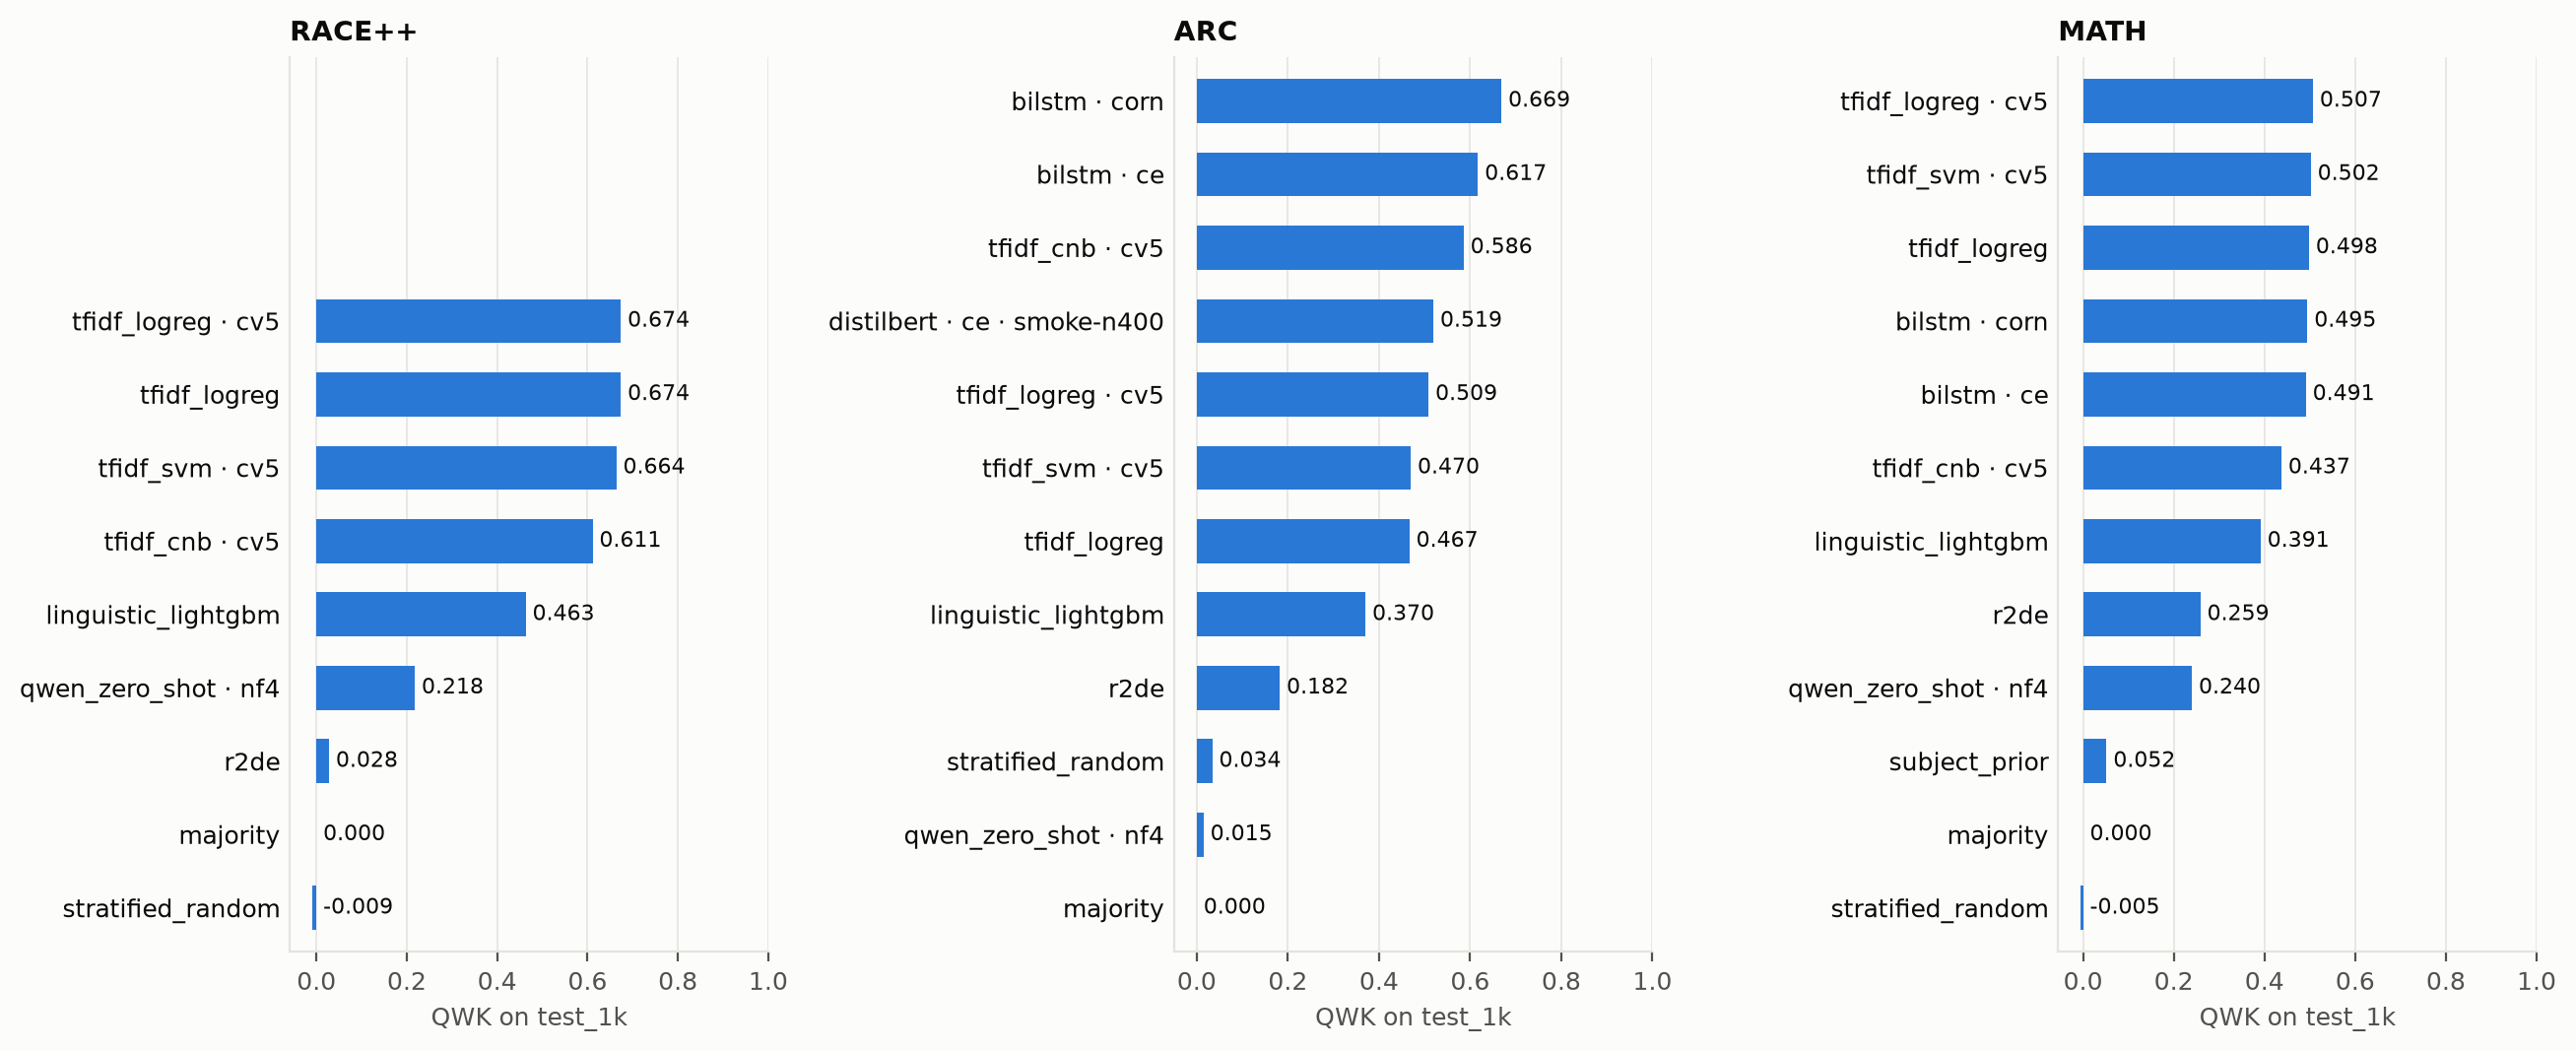

`results/figures/confusion_arc-bilstm-corn-s0.png`

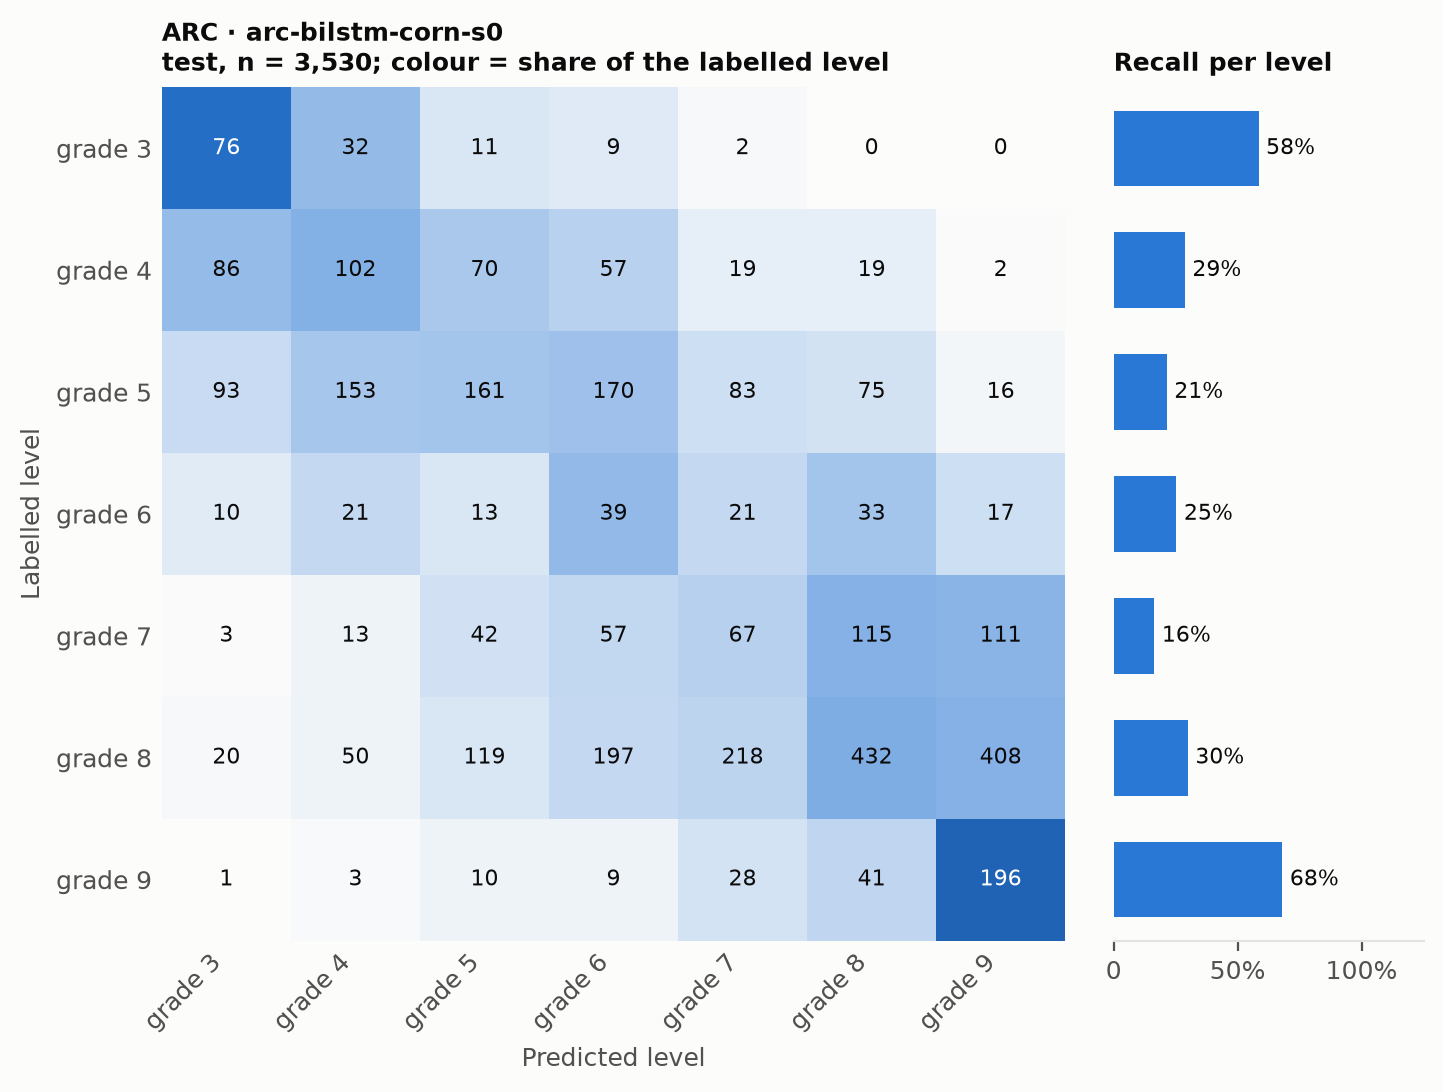

`results/figures/confusion_math-bilstm-corn-s0.png`

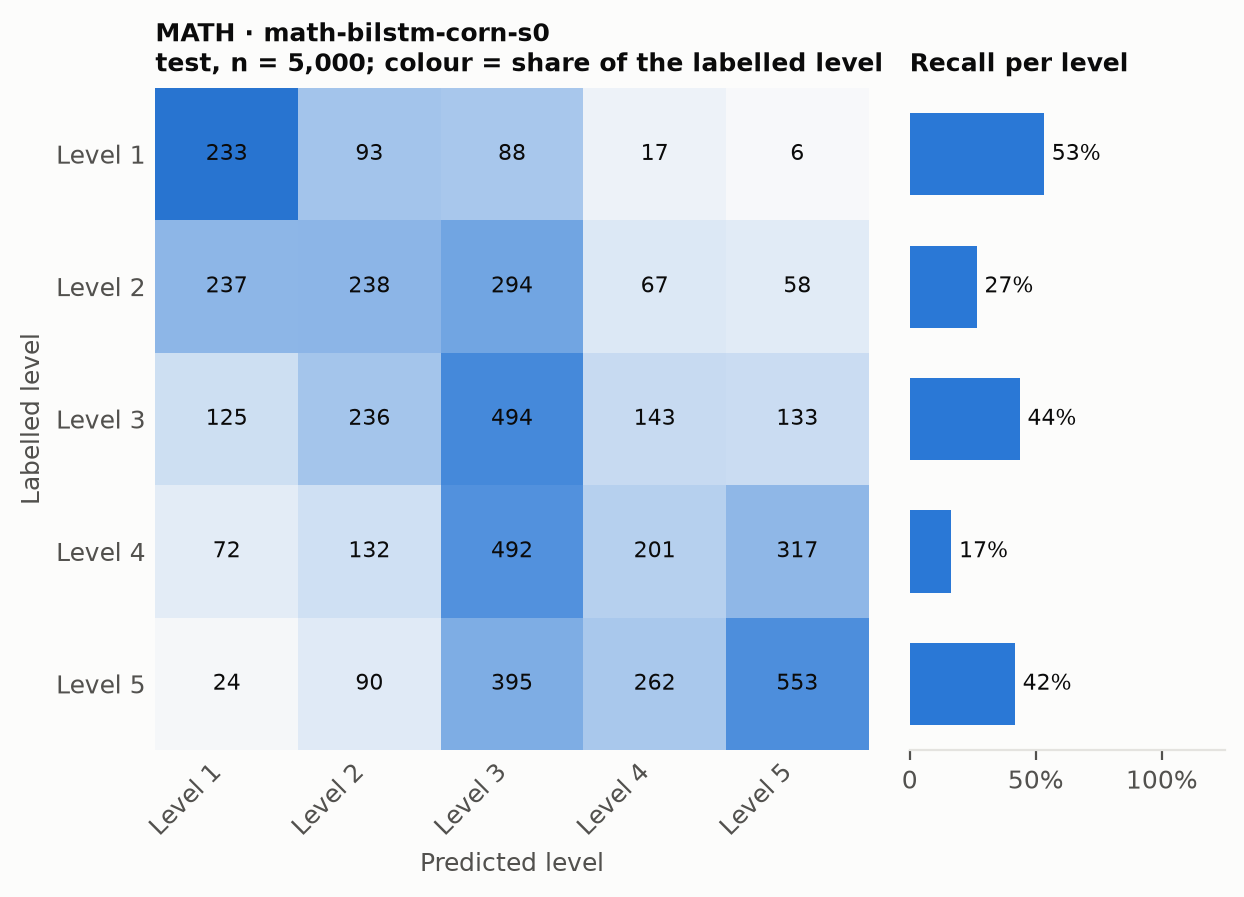

`results/figures/confusion_race-tfidf_logreg-none-s0.png`

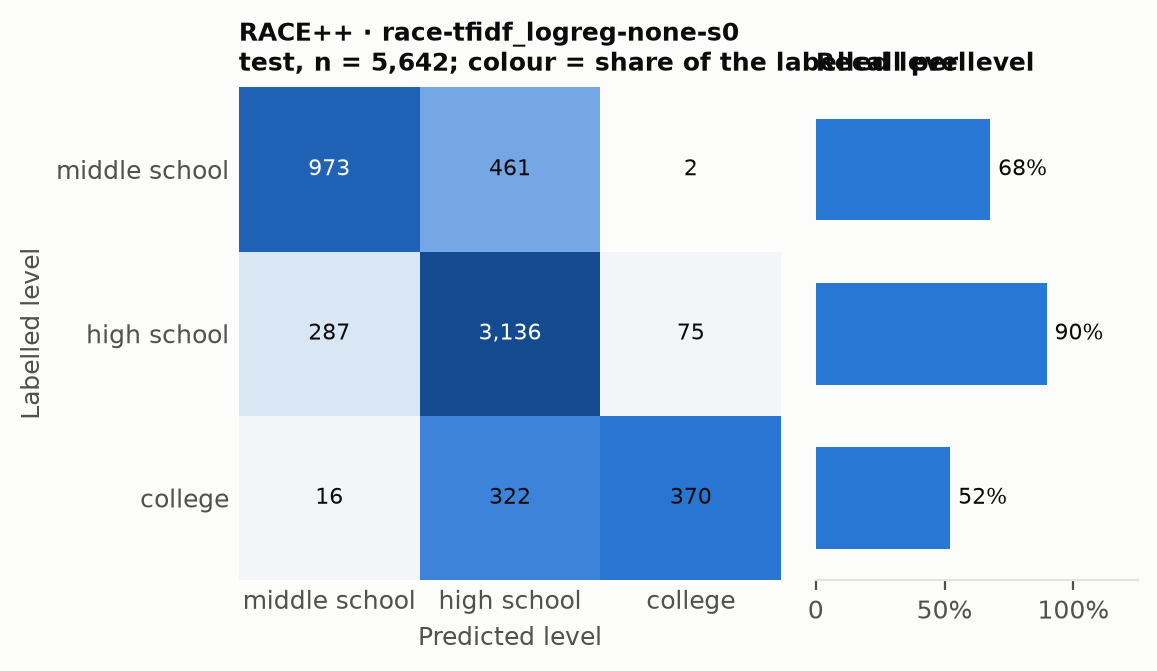

`results/figures/cue_words_arc-distilbert-ce-smoke-n400-s0.png`

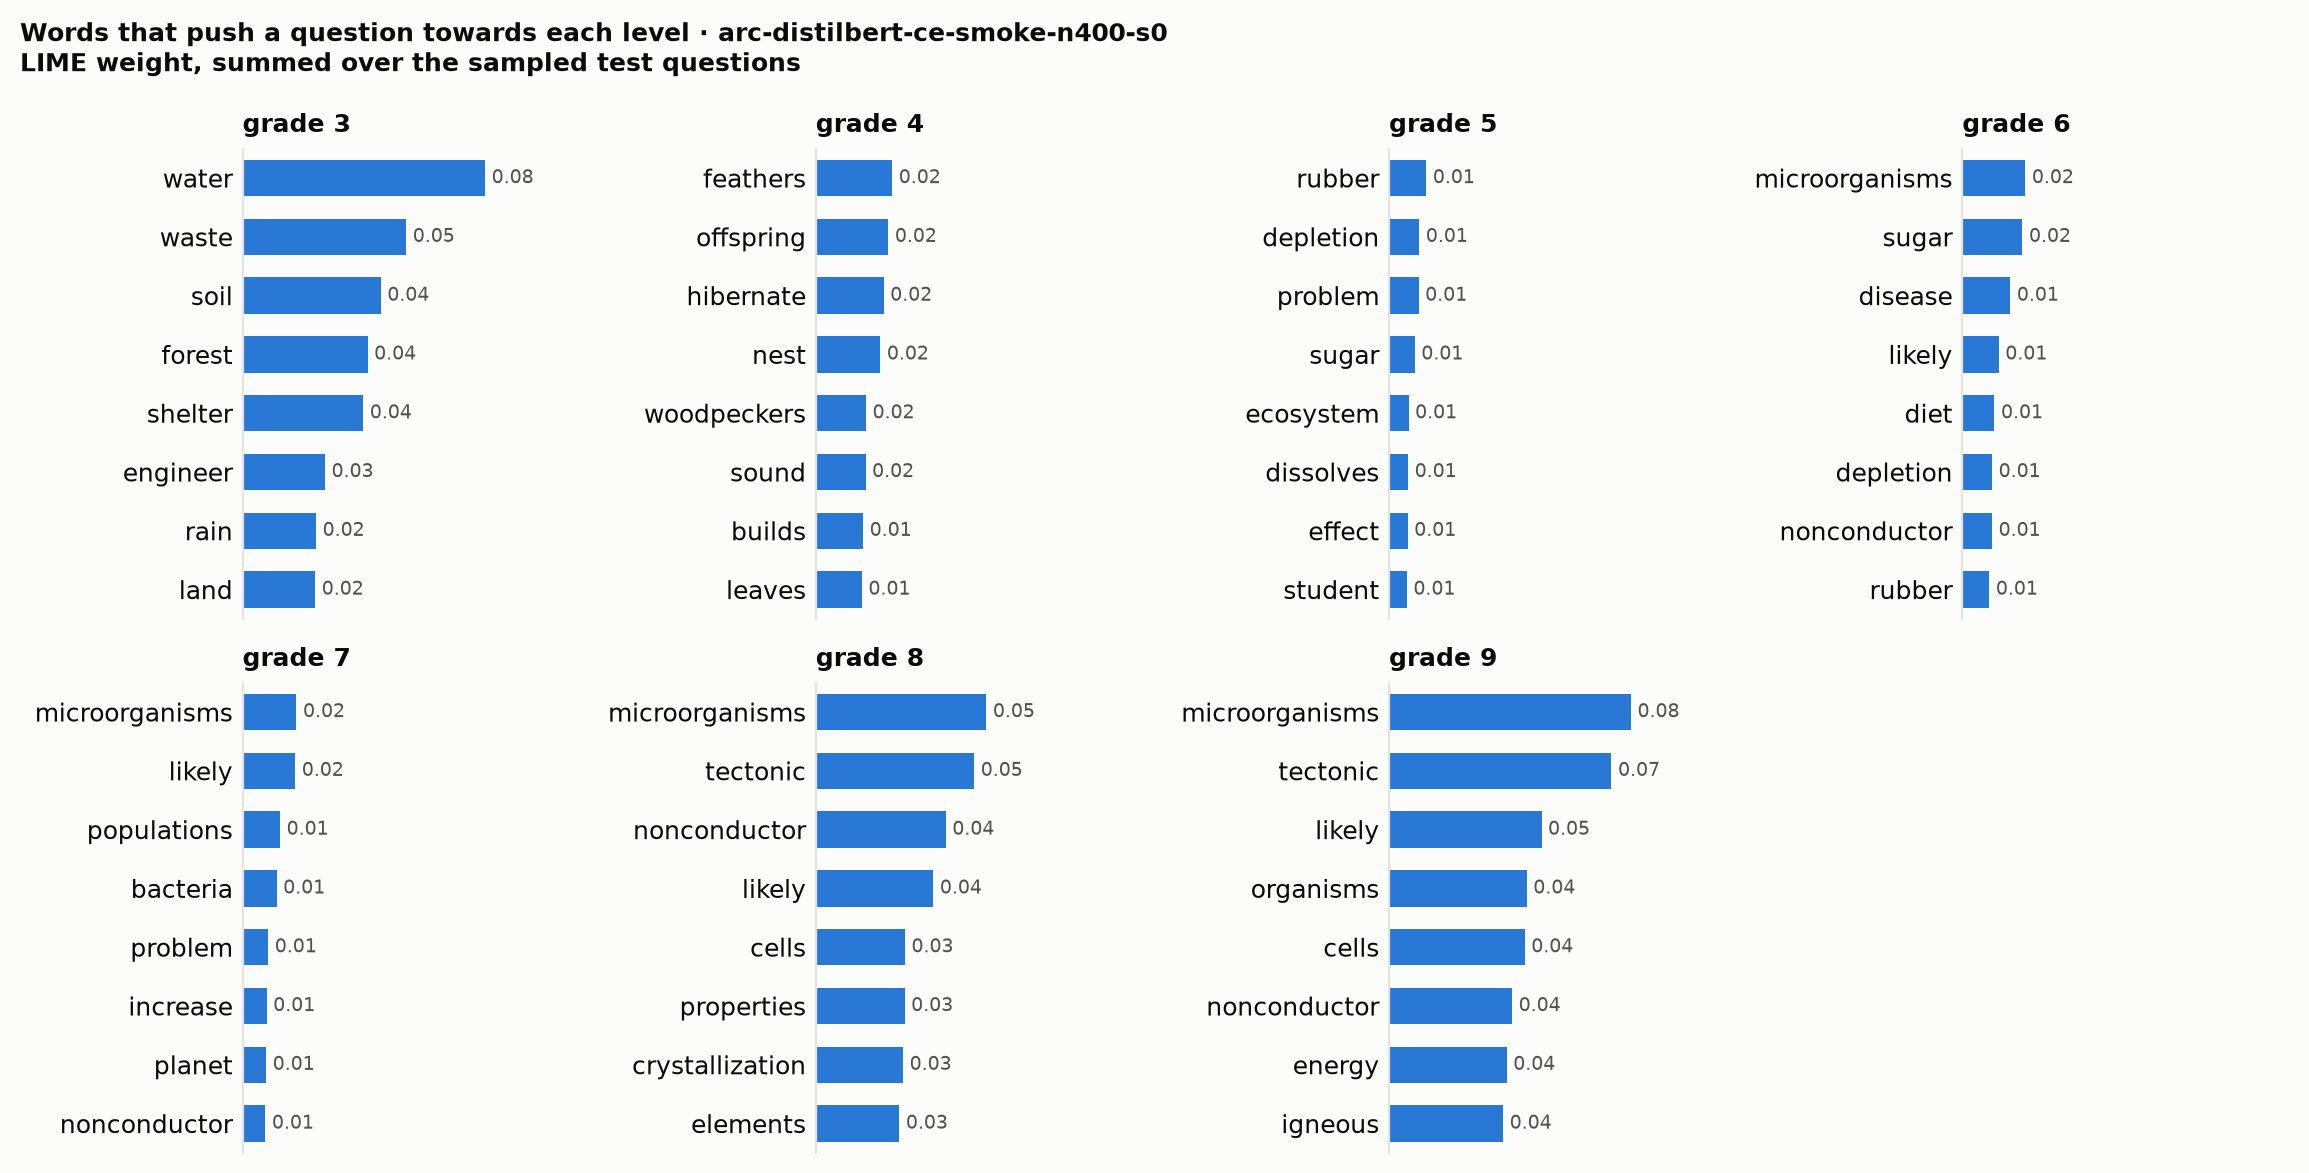

`results/figures/transfer.png`

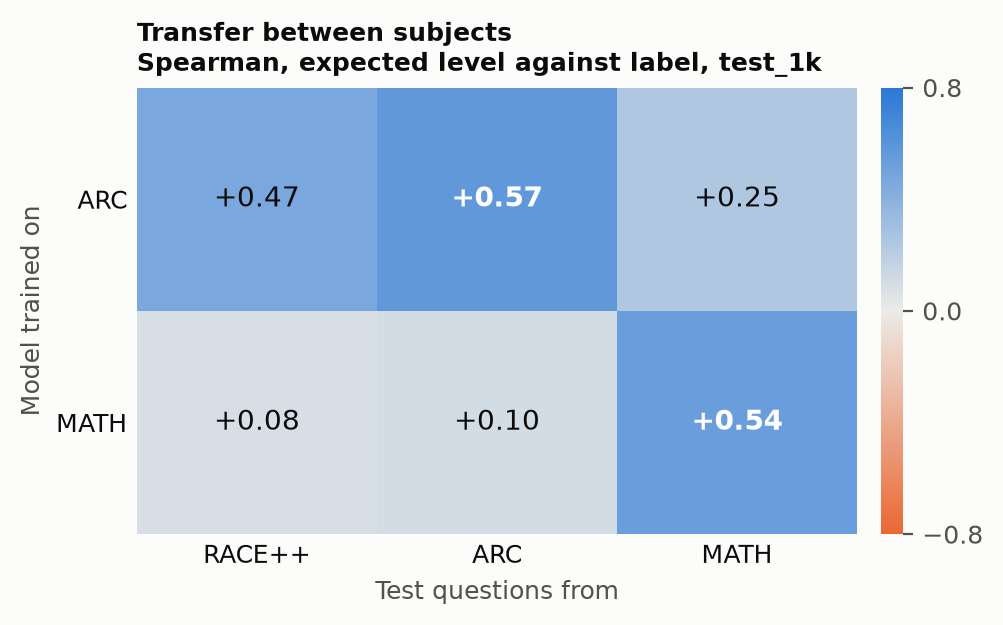

`results/figures/extrapolation.png`

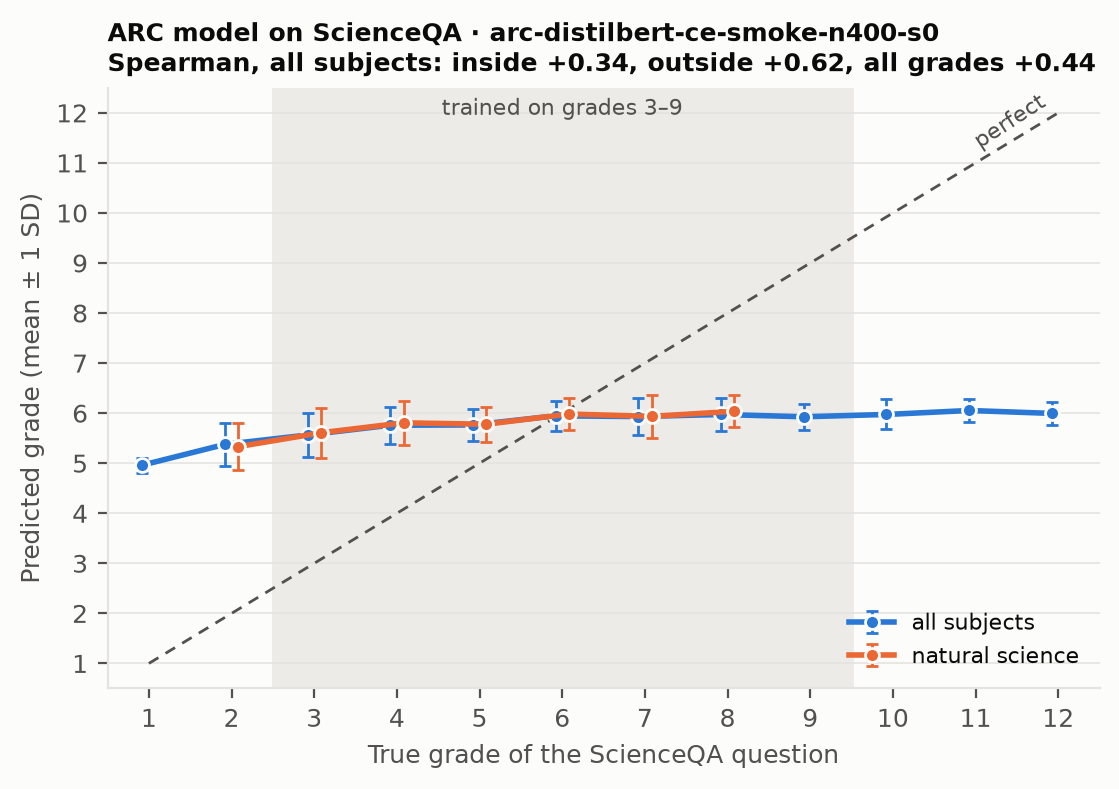

In [15]:
for path in build_figures():
    display(Markdown(f"`{shown(path)}`"))
    display(Image(filename=str(path), width=900))

### 2.3 Is the best model better than the next one?

For each dataset, the run with the best QWK on `dev` is compared with the best run of a different model, on the full `test` split, with the paired bootstrap of section 1.5. Trial runs are left out. The open LLM is scored on `test_1k` only, so it is not part of this comparison.

In [16]:
def best_two(dataset: str) -> tuple[str, str]:
    """Return the run with the best dev QWK on a dataset, and the best run of a different model.

    Only runs with saved test predictions count.
    """
    candidates = runs[(runs["dataset"] == dataset) & ~runs["run_id"].isin(trial)]
    candidates = candidates.dropna(subset=["metrics.dev.qwk"]).sort_values("metrics.dev.qwk", ascending=False)
    with_test = candidates[[
        predictions_file(run_id).exists() and "test" in load_predictions(run_id) for run_id in candidates["run_id"]
    ]]
    first = with_test.iloc[0]
    second = with_test[with_test["model"] != first["model"]].iloc[0]
    return first["run_id"], second["run_id"]


lines = []
for dataset in TITLES:
    first, second = best_two(dataset)
    a, b = load_predictions(first)["test"], load_predictions(second)["test"]
    assert (a["ids"] == b["ids"]).all()  # the same questions in the same order
    result = paired_bootstrap(a["y"], a["output"], b["output"], num_levels=info(dataset).num_levels, metric="qwk")
    lines.append({
        "dataset": dataset, "A": first, "B": second, "QWK of A": result["a"], "QWK of B": result["b"],
        "A − B": result["difference"], "95% low": result["low"], "95% high": result["high"],
    })
pd.DataFrame(lines).round(3)

,dataset,A,B,QWK of A,QWK of B,A − B,95% low,95% high
0,race,race-tfidf_logreg-none-s0,race-tfidf_svm-none-cv5-s0,0.667,0.661,0.006,-0.003,0.014
1,arc,arc-bilstm-corn-s0,arc-tfidf_cnb-none-cv5-s0,0.633,0.544,0.089,0.064,0.114
2,math,math-bilstm-corn-s0,math-tfidf_logreg-none-cv5-s0,0.506,0.507,-0.000,-0.021,0.021


### 2.4 The outputs that need a trained model

These outputs are in the repository, but this notebook does not rebuild them: each one needs the downloaded datasets, and most need a saved model. Run the command in the repository root after `python -m levellens.data.prepare`.

| Output | Command | Needs |
|---|---|---|
| The worst errors, for the human audit: `results/audit/` | `python -m levellens.explain.errors` | saved predictions, datasets |
| LIME cue words: `results/explain/` | `python -m levellens.explain.local <run id>` | a saved model, datasets |
| Transfer matrix and ScienceQA extrapolation: `results/transfer/` | `python -m levellens.explain.transfer` | saved models, datasets |
| Same predictions after loading, and latency on the CPU: `results/export/` | `python -m levellens.export` | saved models, datasets |
| Global SHAP of the feature model: `results/figures/share_d_shap/` | `python -m levellens.explain.global_shap` | the saved LightGBM models, datasets |

A saved model comes from a run with `save_model=true`. The README lists the commands that train every model.

The global SHAP figures below are the files in the repository. For each subject they show how much of the feature model's output comes from each group of features. The captions are in `results/figures/share_d_shap/summary.md`.

`results/figures/share_d_shap/race_global_shap.png`

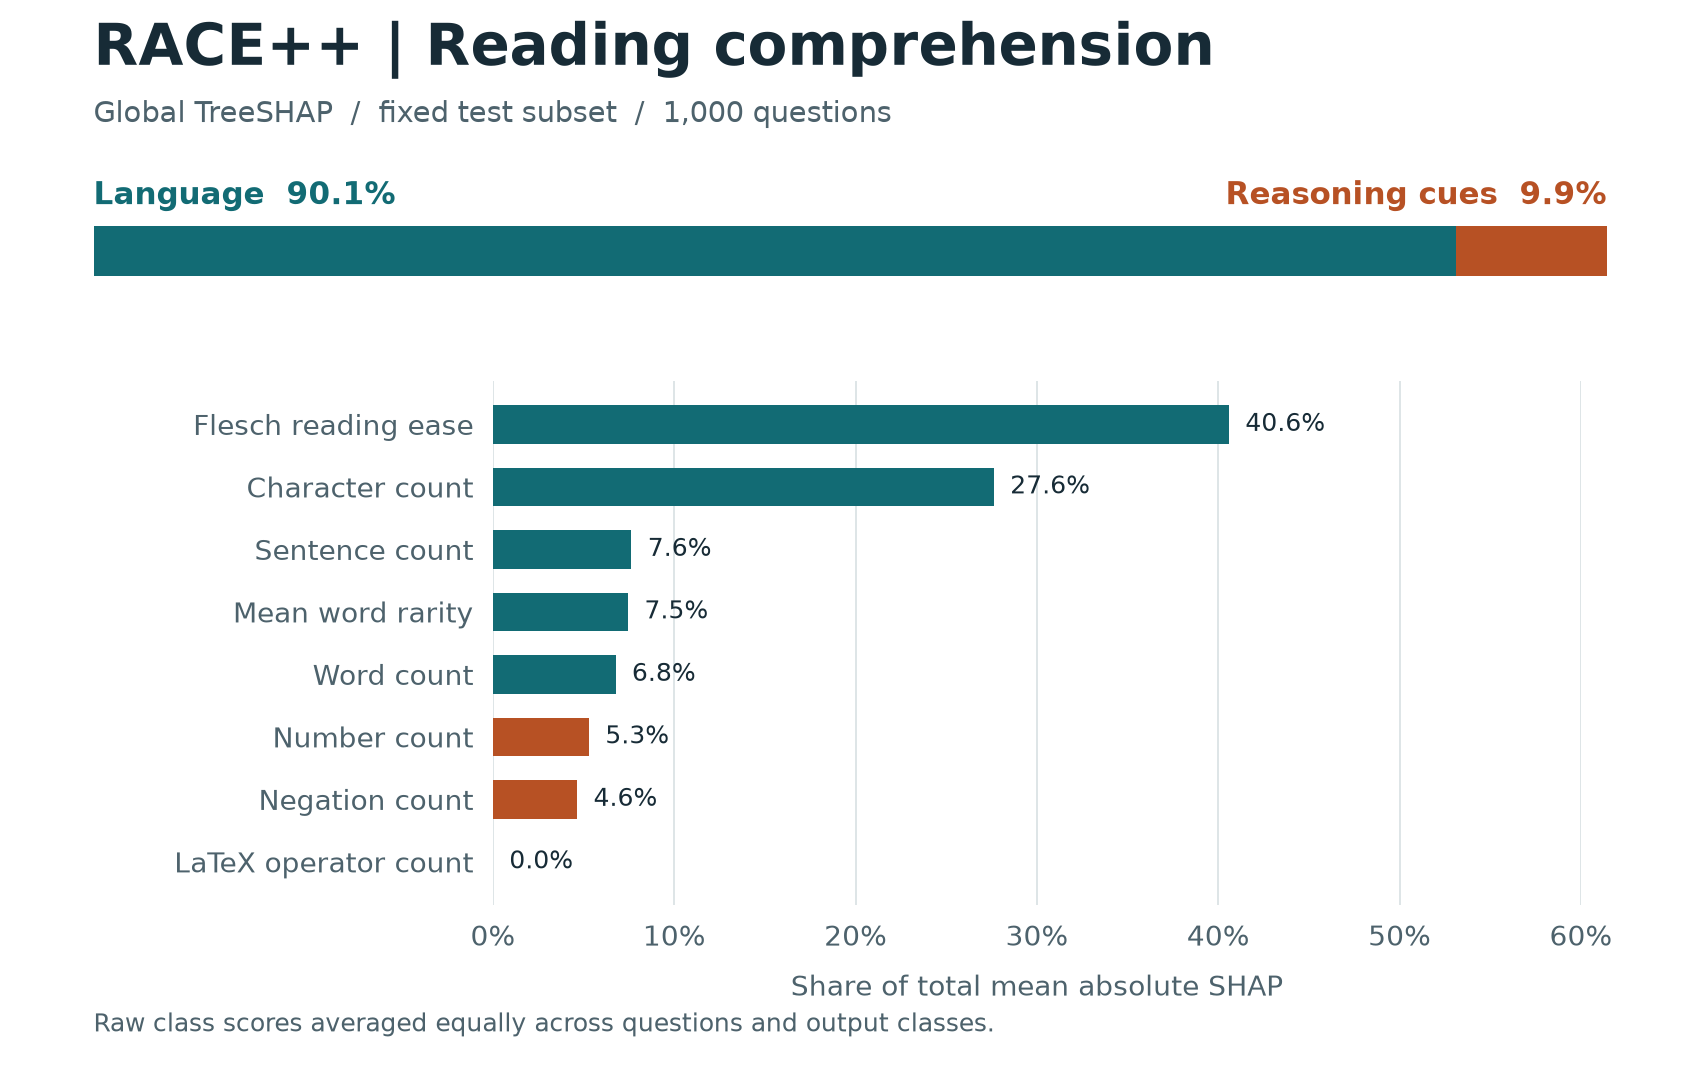

`results/figures/share_d_shap/arc_global_shap.png`

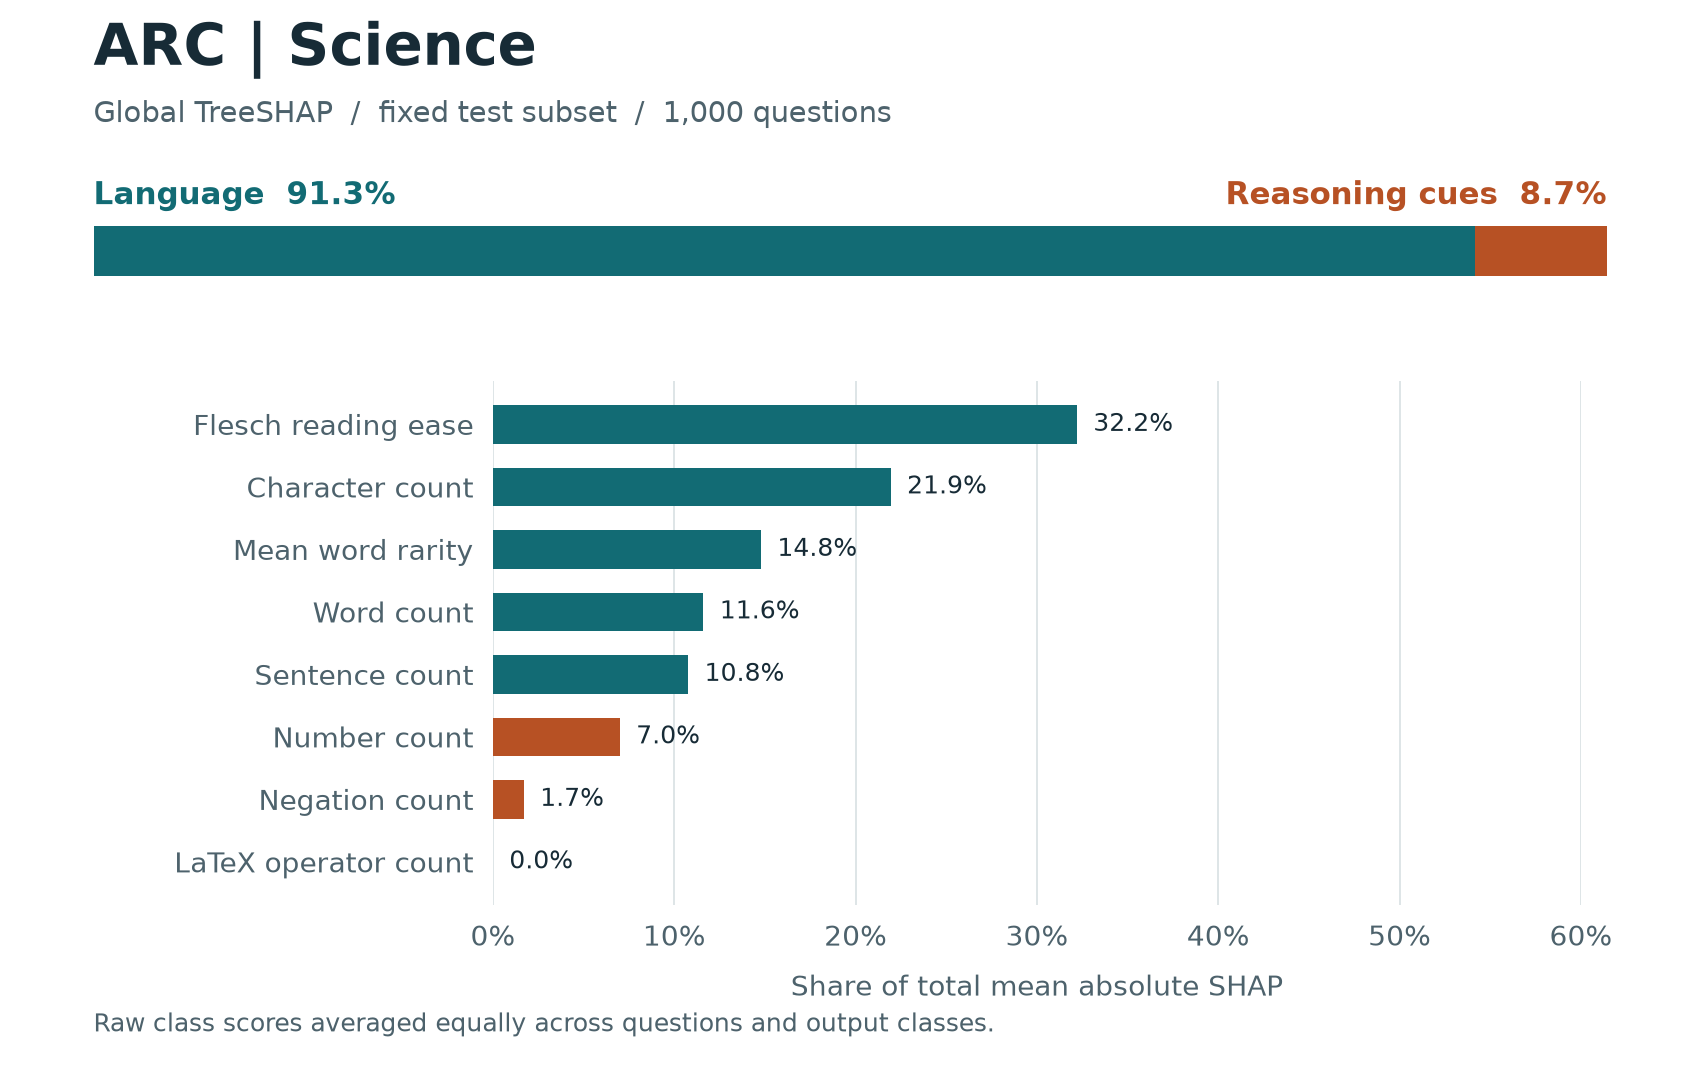

`results/figures/share_d_shap/math_global_shap.png`

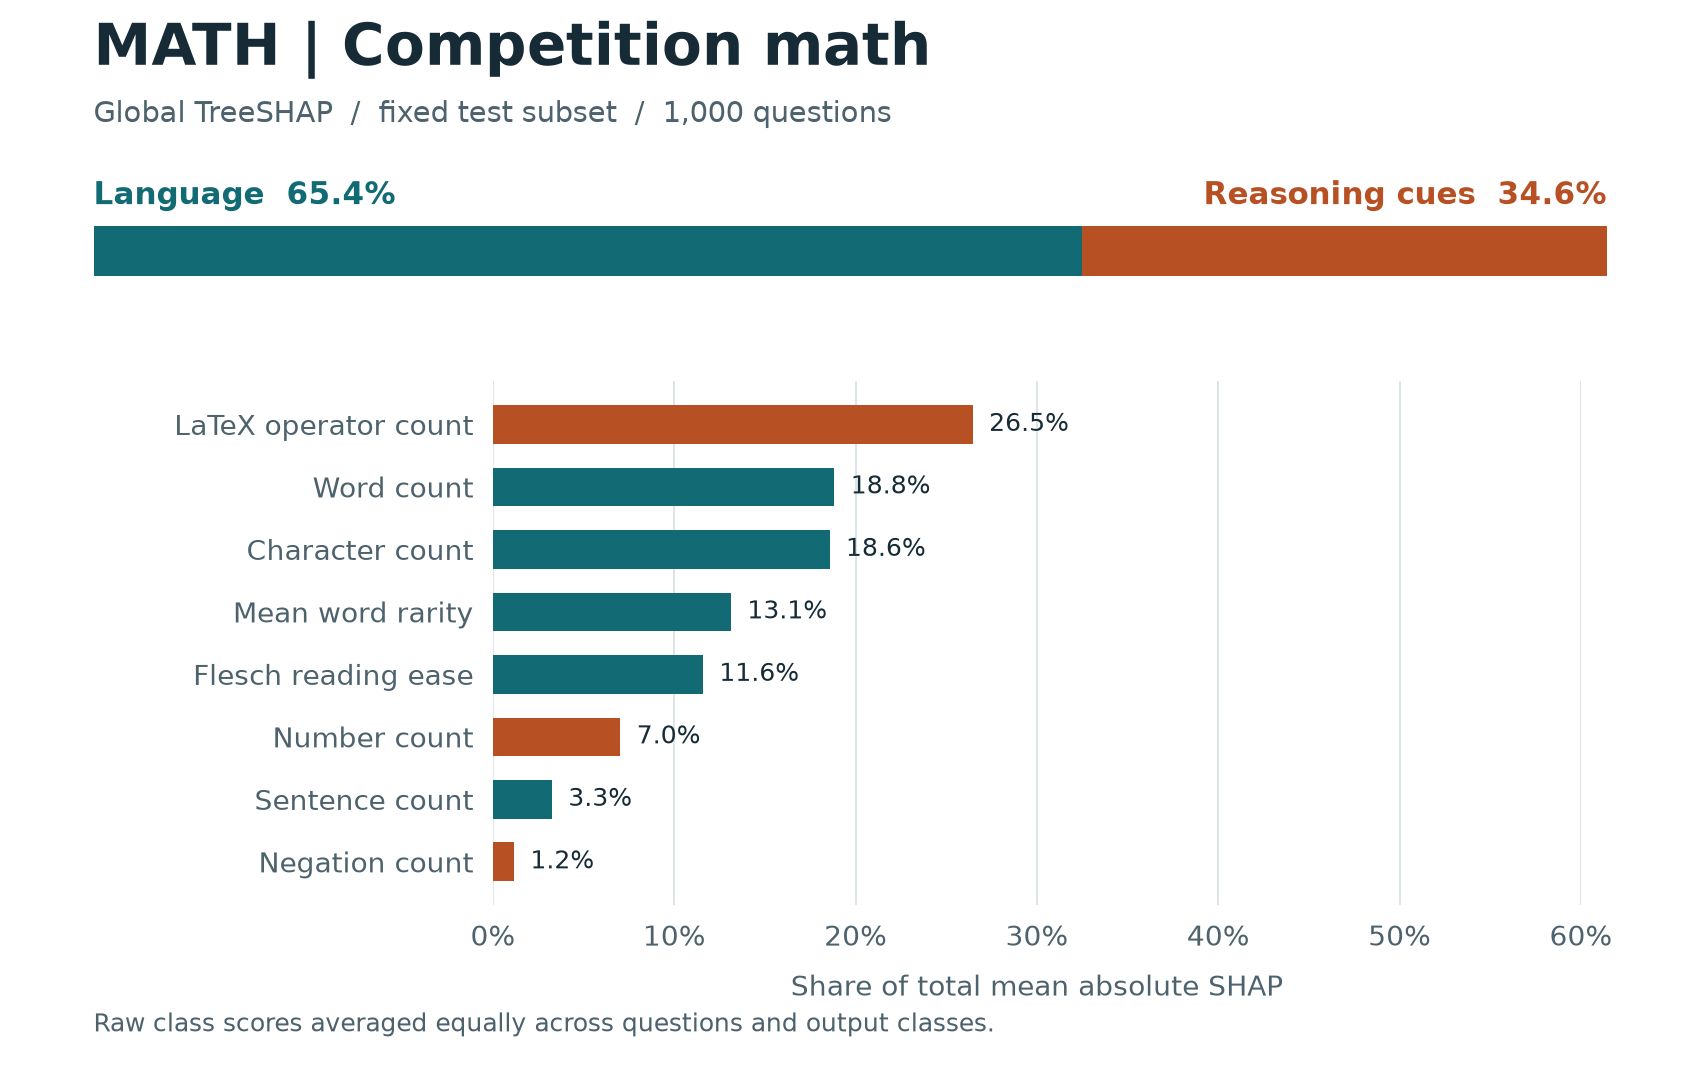

In [17]:
for dataset in TITLES:
    path = results_dir() / "figures" / "share_d_shap" / f"{dataset}_global_shap.png"
    display(Markdown(f"`{shown(path)}`"))
    display(Image(filename=str(path), width=900))